# Can a computer tell a cat from a dog? An honest walkthrough

This notebook walks through the whole project in plain language. You don't need to know machine
learning to follow it: each step says **what** we do and **why**, then shows the result.

**The question:** given a photo of a pet, is it a cat or a dog?

**The data:** the [Oxford-IIIT Pet dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/): 7,349
photos of 37 breeds (12 cat breeds, 25 dog breeds), about 200 photos per breed. License: CC BY-SA 4.0.

**What makes this project different:** it's easy to get an impressive-looking number on this task and
much harder to get an *honest* one. We test three ways and show why they give very different answers.

> **Glossary, as we go**
> - **Model:** a program that learns a pattern from examples instead of being told the rules.
> - **Training set:** the examples the model learns from (the textbook).
> - **Validation set:** examples used to decide when to stop studying (practice quizzes).
> - **Test set:** examples kept locked away until the very end (the final exam).

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from petcnn import config, data, features, preprocess

CAT, DOG = "#2a78d6", "#eb6834"          # one colour per species, used in every chart
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
df = data.load_index()
imgs = np.load(config.PROCESSED / data.CACHE, mmap_mode="r")
print(f"{len(df):,} photos, {df.breed.nunique()} breeds")

7,349 photos, 37 breeds


### The workflow at a glance

```
fetch  →  prepare  →  classic baseline ─┐
(get)     (shrink,     CNN from scratch ─┼→  eval (grade once on the sealed test)  →  deploy to AWS
          dedupe,      ResNet-18 ───────┘                                            (photo in, cat/dog out)
          split)
```

Each arrow is one command (`python -m petcnn <step>`). The sections below follow it in order.

## 1. Look at the data first

Before building anything, look at what we have. How many cats vs dogs? What do the photos look like?

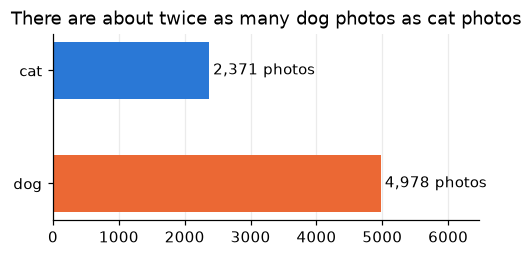

In [2]:
counts = df.groupby(["species", "breed"]).size().reset_index(name="photos")
by_species = df.species.value_counts()
fig, ax = plt.subplots(figsize=(5, 2.2))
ax.barh(["dog", "cat"], [by_species["dog"], by_species["cat"]], color=[DOG, CAT], height=0.5)
for i, s in enumerate(["dog", "cat"]):
    ax.text(by_species[s] + 60, i, f"{by_species[s]:,} photos", va="center")
ax.set_xlim(0, by_species.max() * 1.3)
ax.set_title("There are about twice as many dog photos as cat photos")
ax.grid(axis="y", visible=False)
plt.show()

**Why this matters:** a lazy model could answer "dog" every time and be right about **68%** of the
time. Any score we report has to beat that "always say dog" baseline by a lot to mean anything.
(Training compensates by counting each cat photo a little more, called *class weighting*.)

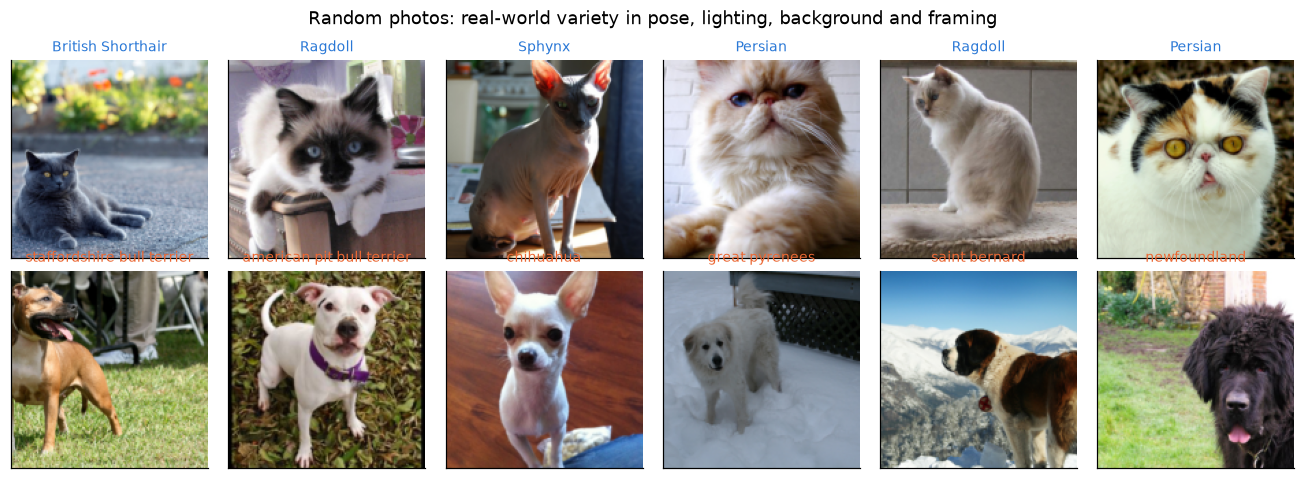

In [3]:
rng = np.random.default_rng(3)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for row, sp in enumerate(["cat", "dog"]):
    pick = rng.choice(df.index[df.species == sp], 6, replace=False)
    for ax, i in zip(axes[row], pick):
        ax.imshow(imgs[i]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(df.breed[i].replace("_", " "), fontsize=9, color=CAT if sp == "cat" else DOG)
fig.suptitle("Random photos: real-world variety in pose, lighting, background and framing")
plt.tight_layout(); plt.show()

Every photo is shrunk to a 144 × 144 pixel square (the shorter side is resized, then the centre is
cut out) and stored once. The whole dataset then takes under 0.5 GB of memory.

**Lesson from the first attempt:** the 2023 version of this project (on Azure) turned every photo into
a large array of decimal numbers up front, used 11 of 14 GB of RAM, and crashed. Keeping photos as
small whole numbers until the moment they're used fixes that.

## 2. Hidden duplicates: the first honesty check

Datasets often contain near-copies of the same photo. If one copy is in the training set and another
in the test set, the model is quizzed on a picture it has already seen, like a student who has
seen the exam answers.

We fingerprint each photo with a *perceptual hash* (a 64-bit summary that barely changes when a
picture is resized or recompressed). Two photos whose fingerprints differ in 4 or fewer bits are
treated as duplicates.

In [4]:
audit = json.loads((config.PROCESSED / "duplicates.json").read_text())
pd.Series(audit["summary"]).to_frame("count")

,count
images,7349
near_duplicate_pairs,43
pairs_crossing_official_trainval_test,24
pairs_with_different_breed_label,0
dropped_official,24
dropped_unseen_breeds,0


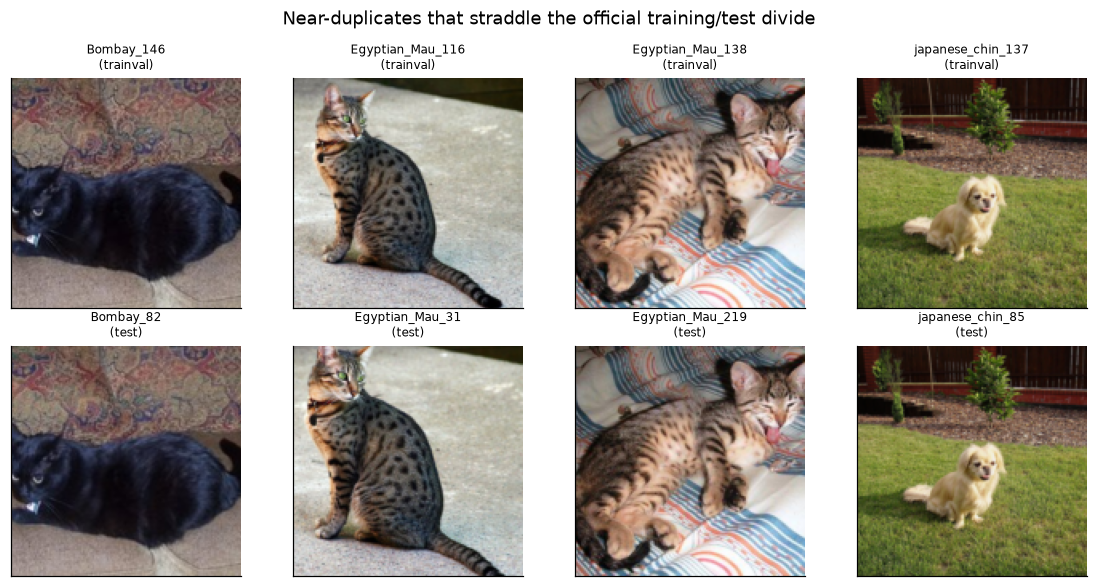

In [5]:
off = dict(zip(df.image, df.official))
crossing = [p for p in audit["pairs"] if off[p[0]] != off[p[1]]][:4]
pos = {name: i for i, name in enumerate(df.image)}
fig, axes = plt.subplots(2, len(crossing), figsize=(2.6 * len(crossing), 5.4))
for col, (a, b) in enumerate(crossing):
    for row, name in enumerate((a, b)):
        ax = axes[row, col]
        ax.imshow(imgs[pos[name]]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{name}\n({off[name]})", fontsize=8)
fig.suptitle("Near-duplicates that straddle the official training/test divide")
plt.tight_layout(); plt.show()

The dataset's own split has **24 photos in its training half that are near-copies of test photos**.
That's small (0.3% of the data) but it's free accuracy a model doesn't deserve, so we remove those
24 from training. Most public notebooks on this dataset never check.

## 3. Three ways to test: one honest, one hard, one broken

| Test | What's in the final exam | What it tells us |
|---|---|---|
| **official** | the dataset's own test half (3,669 photos), duplicates removed from training | the standard, honest score |
| **unseen-breeds** | 12 breeds the model **never** saw while learning (e.g. Sphynx cats, pugs, samoyeds) | does it understand "cat" or did it memorise breeds? |
| **leaky-2023** | the same photos it trained on | reproduces the 2023 bug; how good a *cheating* score looks |

The 2023 notebook's bug, visible in its screenshot, was one line:
`train_loader = DataLoader(test_set, ...)`. It studied the exam.

In [6]:
tbl = pd.DataFrame({s: df[f"split_{s}"].value_counts() for s in data.SCHEMES}).fillna(0).astype(int)
tbl.loc[["train", "val", "test", "drop"]]

,official,unseen-breeds,leaky-2023
train,3102,4208,0
val,554,746,0
test,3669,2395,3669
drop,24,0,3680


In [7]:
unseen = config.load()["data"]["unseen_breeds"]
print("Never seen during training (unseen-breeds test):")
print("  cats:", ", ".join(unseen["cat"]))
print("  dogs:", ", ".join(unseen["dog"]))

Never seen during training (unseen-breeds test):
  cats: Bengal, Maine_Coon, Russian_Blue, Sphynx
  dogs: beagle, boxer, chihuahua, havanese, newfoundland, pug, samoyed, shiba_inu


## 4. The old-school approach first: is deep learning even needed?

Before using a neural network, try the classic recipe: describe each photo with hand-made
measurements, then fit a simple statistical model.

- **Colour histogram:** how much of each colour is in the picture.
- **HOG (histogram of oriented gradients):** which directions the edges point in each small patch,
  a rough sketch of shapes like ears and snouts.

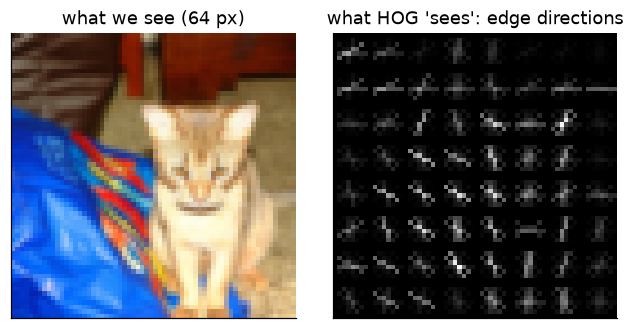

In [8]:
from skimage.feature import hog
from skimage.color import rgb2gray
i = int(df.index[(df.species == "cat")][5])
small = features._small(imgs[i])
_, viz = hog(rgb2gray(small), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(small); axes[0].set_title("what we see (64 px)")
axes[1].imshow(viz, cmap="gray"); axes[1].set_title("what HOG 'sees': edge directions")
for ax in axes: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

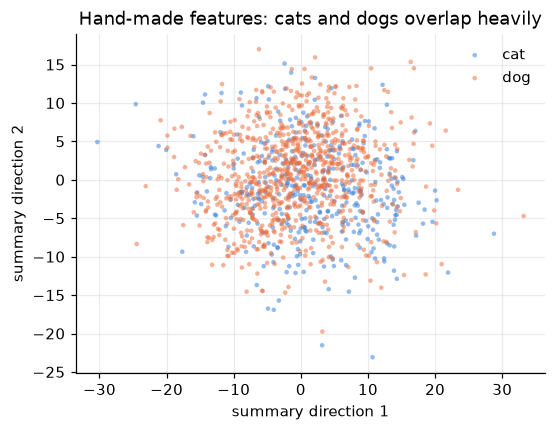

In [9]:
from sklearn.decomposition import PCA
sample = df.sample(1200, random_state=0)
F = features.extract(np.asarray(imgs[sample.index.to_numpy()]))
xy = PCA(2, random_state=0).fit_transform((F - F.mean(0)) / (F.std(0) + 1e-6))
fig, ax = plt.subplots(figsize=(5.5, 4))
for sp, c in (("cat", CAT), ("dog", DOG)):
    m = (sample.species == sp).to_numpy()
    ax.scatter(xy[m, 0], xy[m, 1], s=9, alpha=0.5, color=c, label=sp, edgecolors="none")
ax.legend(frameon=False); ax.set_xlabel("summary direction 1"); ax.set_ylabel("summary direction 2")
ax.set_title("Hand-made features: cats and dogs overlap heavily")
plt.show()

Squashing the 1,812 hand-made measurements down to two directions shows the problem: cats and dogs
land mostly on top of each other. Colour and edges alone don't separate them well. That leaves room
for a neural network, which **learns its own features** from the pixels.

## 5. The neural network (a CNN)

A **convolutional neural network (CNN)** looks at an image through many small sliding windows. Early
layers learn to spot edges and textures, later layers combine them into parts (ears, eyes, fur),
and the last layer weighs the evidence for "cat" vs "dog". Ours is small: 4 blocks, 1.2 million
learned numbers, trained from scratch on about 3,100 photos.

We also try **transfer learning**: ResNet-18, a larger network (11 million numbers) that was
first trained on ImageNet, 1.2 million everyday photos in 1,000 categories. It already knows what fur,
eyes and ears look like; we only teach it the last step. One caveat: ImageNet's categories include
many of these exact breeds, so the network has a head start that the from-scratch model doesn't.

Two habits keep both honest:
- **Augmentation:** each time a photo is shown, it's randomly shifted and mirrored, so the model
  can't memorise exact pixels.
- **Early stopping:** after each pass through the data we check the practice quiz (validation
  set) and stop when it stops improving, then keep the best version.

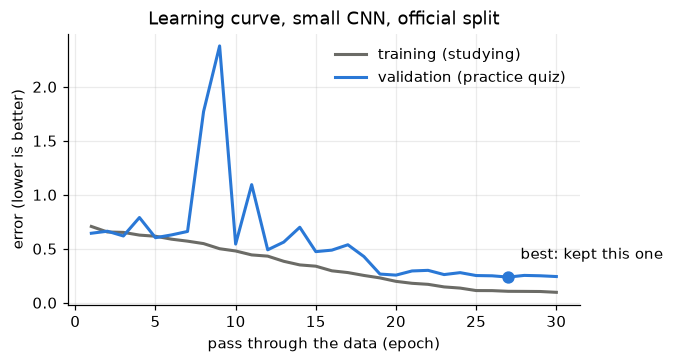

In [10]:
hist_path = config.MODELS / "smallcnn-official" / "history.json"
if hist_path.exists():
    h = pd.DataFrame(json.loads(hist_path.read_text()))
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(h.epoch, h.train_loss, lw=2, color="#6b6b66", label="training (studying)")
    ax.plot(h.epoch, h.val_loss, lw=2, color=CAT, label="validation (practice quiz)")
    best = h.val_loss.idxmin()
    ax.scatter([h.epoch[best]], [h.val_loss[best]], s=50, color=CAT, zorder=3)
    ax.annotate("best: kept this one", (h.epoch[best], h.val_loss[best]), xytext=(8, 12), textcoords="offset points")
    ax.set_xlabel("pass through the data (epoch)"); ax.set_ylabel("error (lower is better)")
    ax.legend(frameon=False); ax.set_title("Learning curve, small CNN, official split")
    plt.show()
else:
    print("Train first: python -m petcnn train --arch smallcnn --scheme official")

## 6. Results: the honest, the hard and the broken

**Accuracy** is the share of test photos labelled correctly. The range in brackets is a 95%
confidence interval: re-running the exam with a different sample of photos would land in that range.
**Balanced accuracy** averages the cat score and the dog score, so "always say dog" gets 50%, not 68%.

In [11]:
rows = []
for f in sorted(config.RESULTS.glob("*/*.json")):
    r = json.loads(f.read_text())
    if r.get("trained_on", r["scheme"]) != r["scheme"]:
        continue                                   # only score a model on the scheme it was built for
    rows.append({"test": r["scheme"], "system": r["name"], "accuracy": r["accuracy"],
                 "95% range": f"{r['accuracy_ci95'][0]:.1%} - {r['accuracy_ci95'][1]:.1%}",
                 "balanced accuracy": r["balanced_accuracy"],
                 "cat recall": r["per_class"]["cat"]["recall"], "dog recall": r["per_class"]["dog"]["recall"]})
res = pd.DataFrame(rows)
res.style.format({c: "{:.1%}" for c in ["accuracy", "balanced accuracy", "cat recall", "dog recall"]}) if len(res) else "no results yet"

,test,system,accuracy,95% range,balanced accuracy,cat recall,dog recall
0,leaky-2023,smallcnn-leaky-2023,98.7%,98.3% - 99.0%,98.8%,99.3%,98.4%
1,official,classic-hog-logreg,70.2%,68.6% - 71.7%,68.8%,64.8%,72.8%
2,official,resnet18-official,97.2%,96.7% - 97.7%,97.5%,98.5%,96.6%
3,official,smallcnn-official,91.5%,90.5% - 92.3%,91.2%,90.2%,92.1%
4,unseen-breeds,classic-hog-logreg,64.9%,62.8% - 66.6%,64.1%,61.9%,66.4%
5,unseen-breeds,resnet18-unseen-breeds,94.0%,93.0% - 94.9%,92.7%,88.8%,96.6%
6,unseen-breeds,smallcnn-unseen-breeds,87.5%,86.1% - 88.8%,87.2%,86.1%,88.2%


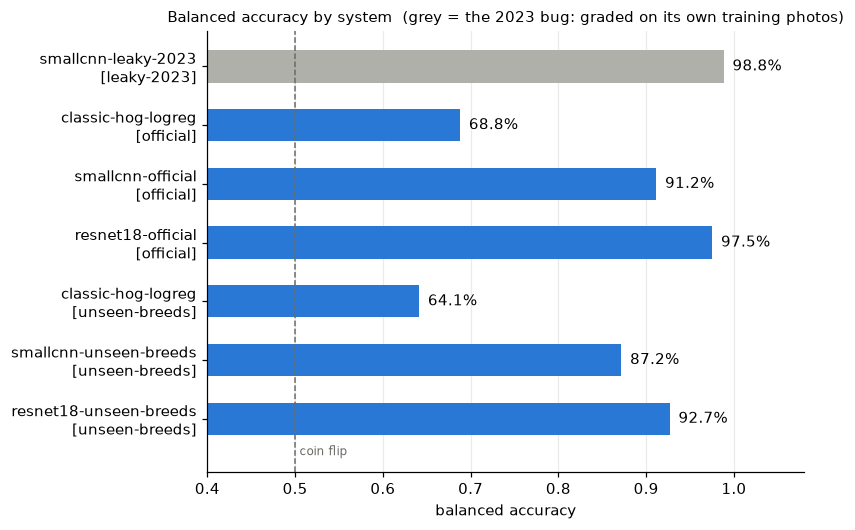

In [12]:
if len(res):
    order = [("leaky-2023", "smallcnn-leaky-2023"),
             ("official", "classic-hog-logreg"), ("official", "smallcnn-official"), ("official", "resnet18-official"),
             ("unseen-breeds", "classic-hog-logreg"), ("unseen-breeds", "smallcnn-unseen-breeds"),
             ("unseen-breeds", "resnet18-unseen-breeds")]
    shown = [(t, s) for t, s in order if ((res.test == t) & (res.system == s)).any()]
    vals = [res[(res.test == t) & (res.system == s)].iloc[0]["balanced accuracy"] for t, s in shown]
    labels = [f"{s}\n[{t}]" for t, s in shown]
    fig, ax = plt.subplots(figsize=(7, 0.6 * len(shown) + 1))
    colors = ["#b0b0aa" if t == "leaky-2023" else CAT for t, _ in shown]
    ax.barh(labels[::-1], vals[::-1], color=colors[::-1], height=0.55)
    for y, v in enumerate(vals[::-1]):
        ax.text(v + 0.01, y, f"{v:.1%}", va="center")
    ax.axvline(0.5, color="#6b6b66", lw=1, ls="--")
    ax.text(0.505, -0.45, "coin flip", fontsize=8, color="#6b6b66", va="top")
    ax.set_xlim(0.4, 1.08); ax.set_xlabel("balanced accuracy"); ax.grid(axis="y", visible=False)
    leaky = any(t == "leaky-2023" for t, _ in shown)
    ax.set_title("Balanced accuracy by system" + ("  (grey = the 2023 bug: graded on its own training photos)" if leaky else ""),
                 fontsize=10)
    ax.set_ylim(-0.9, len(shown) - 0.4)
    plt.show()

### Which unseen breeds are hardest?

Break the unseen-breeds score down by breed. If the model really learned "cat" and "dog", every
breed should score about the same.

/home/williemaize/workspace/projects/pet-cnn/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:228: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


CUDA unusable (torch.cuda.is_available() is False); using CPU


CUDA unusable (torch.cuda.is_available() is False); using CPU


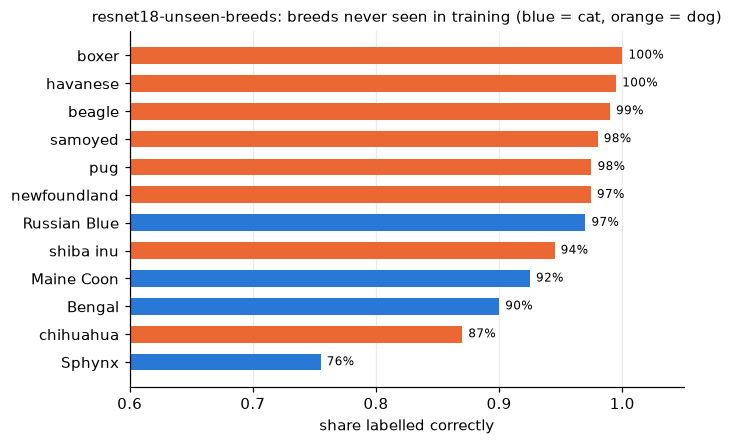

,,smallcnn-unseen-breeds,resnet18-unseen-breeds
breed,species,,
Sphynx,cat,74%,76%
chihuahua,dog,90%,87%
Bengal,cat,88%,90%
Maine_Coon,cat,90%,92%
shiba_inu,dog,82%,94%
Russian_Blue,cat,92%,97%
newfoundland,dog,86%,97%
pug,dog,86%,98%
samoyed,dog,91%,98%


In [13]:
from petcnn import train as _train
per_breed = {}
for name in ("smallcnn-unseen-breeds", "resnet18-unseen-breeds"):
    if not (config.MODELS / name / "model.safetensors").exists():
        continue
    net, _ = _train.load_model(name)
    x, y, rows = data.load("unseen-breeds", "test", "species")
    rows["correct"] = _train.predict_proba(net, x).argmax(1) == y
    per_breed[name] = rows.groupby(["breed", "species"]).correct.mean()
if per_breed:
    pb = pd.DataFrame(per_breed).sort_values(list(per_breed)[-1])
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    names = [b.replace("_", " ") for b, _ in pb.index]
    colors = [CAT if sp == "cat" else DOG for _, sp in pb.index]
    col = list(per_breed)[-1]
    ax.barh(names, pb[col], color=colors, height=0.6)
    for yv, v in enumerate(pb[col]):
        ax.text(v + 0.005, yv, f"{v:.0%}", va="center", fontsize=8)
    ax.set_xlim(0.6, 1.05); ax.set_xlabel("share labelled correctly"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{col}: breeds never seen in training (blue = cat, orange = dog)", fontsize=10)
    plt.show()
    display(pb.style.format("{:.0%}"))

**Hairless Sphynx cats are the hardest** for both models (about 3 in 4 right). Every cat the model
studied had fur, so a cat without fur looks less like "cat". This is the kind of blind spot a single
headline number hides, and it's why the per-breed view matters.

**How to read this**

- The **leaky** score looks great because the model is graded on photos it studied. Numbers like
  that are what you get when the test set leaks into training. Treat a near-perfect score as a
  warning sign, not a win.
- The **official** score is the honest one for breeds the model has seen.
- The **unseen-breeds** score is the toughest and most realistic: in the real world, people upload
  breeds and mixes the model has never seen.

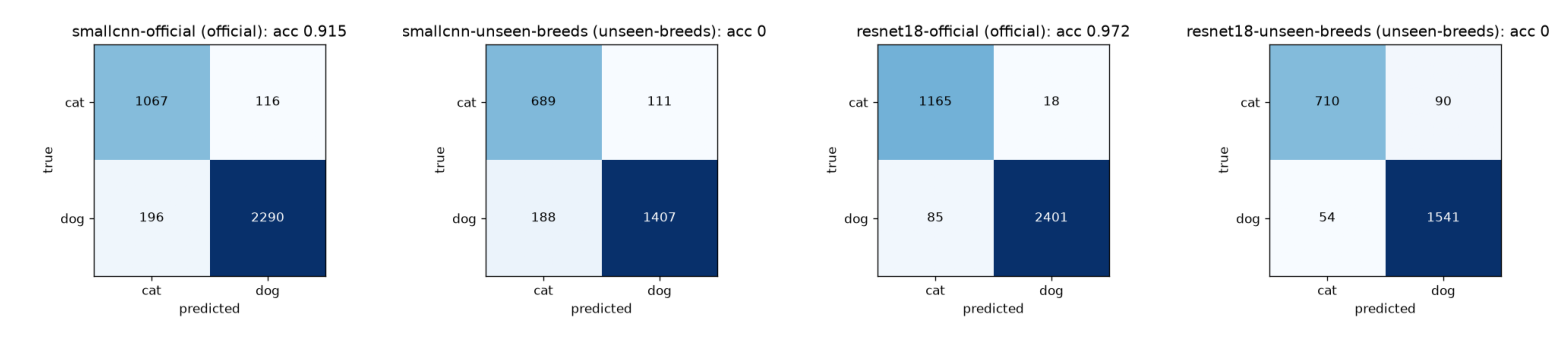

In [14]:
pngs = [config.RESULTS / s / f"{m}-{s}_confusion.png" for m in ("smallcnn", "resnet18") for s in ("official", "unseen-breeds")]
pngs = [p for p in pngs if p.exists()]
if pngs:
    fig, axes = plt.subplots(1, len(pngs), figsize=(3.6 * len(pngs), 3.2))
    for ax, p in zip(np.atleast_1d(axes), pngs):
        ax.imshow(Image.open(p)); ax.axis("off")
    plt.tight_layout(); plt.show()

A **confusion matrix** counts each kind of mistake: rows are the truth, columns the model's answer.
The diagonal is correct answers; the off-diagonal boxes show whether the model mostly mistakes cats
for dogs or the reverse.

## 7. Try it: the same code the cloud endpoint runs

The deployed model on AWS runs `serve/inference.py`. Here we run those exact functions on a few test
photos, so what you see here is what the endpoint would return.

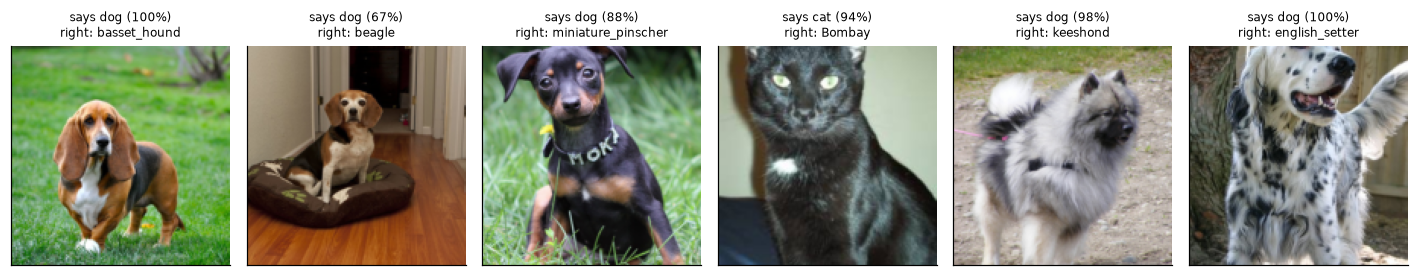

In [15]:
import importlib.util, io
from petcnn import models as _models
sys.modules.setdefault("models", _models); sys.modules.setdefault("preprocess", preprocess)
spec = importlib.util.spec_from_file_location("inference", ROOT / "serve" / "inference.py")
inf = importlib.util.module_from_spec(spec); spec.loader.exec_module(inf)

name = "smallcnn-official"
if (config.MODELS / name / "model.safetensors").exists():
    model = inf.model_fn(str(config.MODELS / name))
    test = df[df.split_official == "test"].sample(6, random_state=7)
    fig, axes = plt.subplots(1, 6, figsize=(13, 2.8))
    for ax, (_, row) in zip(axes, test.iterrows()):
        raw = (config.RAW / "images" / f"{row.image}.jpg").read_bytes()
        out = json.loads(inf.output_fn(inf.predict_fn(inf.input_fn(raw, "image/jpeg"), model), "application/json"))
        ok = out["label"] == row.species
        ax.imshow(imgs[pos[row.image]]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"says {out['label']} ({out['confidence']:.0%})\n{'right' if ok else 'WRONG'}: {row.breed}", fontsize=8)
    plt.tight_layout(); plt.show()

## 8. How it runs on AWS (replacing the 2023 Azure setup)

| Step | 2023 (Azure) | Now (AWS) | Why |
|---|---|---|---|
| Store photos | Blob storage | **S3** | private bucket, old files auto-expire |
| Train | Notebook VM: ran out of memory | **Your own computer** (CPU; a GPU makes it ~10x faster) | small photos in memory fit easily; no cloud bill. A SageMaker training job is wired up for later but not used |
| Serve | not reached | **SageMaker Serverless endpoint** | costs nothing while idle, starts on demand |
| Public access | not reached | **API Gateway** with an API key + daily quota, optional `pets.willieman.com` | anyone with the key can send a photo; the quota caps the bill |

```
photo --> API Gateway (API key, 2 req/s, 500/day) --> SageMaker serverless endpoint --> {"label": "cat", ...}
```

See the README for the commands, and `config.yaml` for every setting in one place.

## 9. What we learned

1. **Check what the model is tested on.** The one-line 2023 bug (training on the test set) turns a
   mediocre model into a "great" one on paper.
2. **Look for duplicates** across the training/test divide before trusting a score.
3. **Test on something genuinely new** (unseen breeds). It's the closest thing to real-world use.
4. **Keep data small in memory** until it's needed; it fixed the original out-of-memory crash.
5. **Beat a simple baseline** (always "dog"; hand-made features) before reaching for deep learning.